# Кейс 2А: стартовый ноутбук

По тексту поста `text` и утверждению `claim` нужно предсказать метку. Метрика — macro-F1.

## Как запустить

1. Распакуй `train.csv` и `test.csv` в одну папку. Помести рядом `requirements.txt`.
2. Для локального запуска установи зависимости: `python -m pip install -r requirements.txt`. Проверенная локальная среда: Python 3.14.7. В Colab загрузи `requirements.txt` в рабочую папку и выполни в отдельной ячейке `!pip install -r requirements.txt`, затем перезапусти среду выполнения.
3. В первой вычислительной ячейке укажи `DATA_DIR` — путь к папке с CSV (по умолчанию текущая папка).
4. Выполни вычислительные ячейки по порядку сверху вниз.
5. Загрузи полученный `submission.csv` на платформу как файл с предсказаниями.


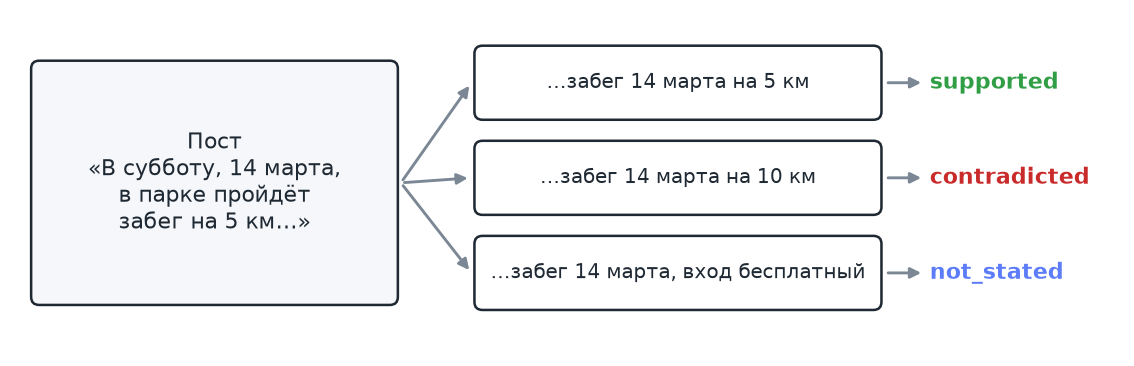

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import GroupShuffleSplit

DATA_DIR = Path('.')  # папка с train.csv и test.csv
SEED = 42

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
print(train.shape, test.shape)
train.label.value_counts()

(6118, 4) (2634, 3)


label
supported       2136
contradicted    2099
not_stated      1883
Name: count, dtype: int64

In [2]:
train.sample(3, random_state=SEED)

,id,text,claim,label
4969,149430d03d95,**💥Благодаря курсу от КУПНО Нижегородский край...,⟦e:mqltlyfsqn⟧ обладает кандидатской степенью ...,contradicted
4666,8bf4408e2d42,**🦠****Роскачество выявило кишечную палочку и ...,В «Мишке на полюсе» нашли бактерии группы кише...,not_stated
4728,2f5a590a11c2,[​​](⟦e:zgbz5cq73t⟧ отменяет в Москве ограниче...,В Москве отменяют ограничения на работу ночных...,not_stated


## Как устроен бейзлайн

Два набора признаков склеиваются в один вектор, а классификатор выбирает метку.

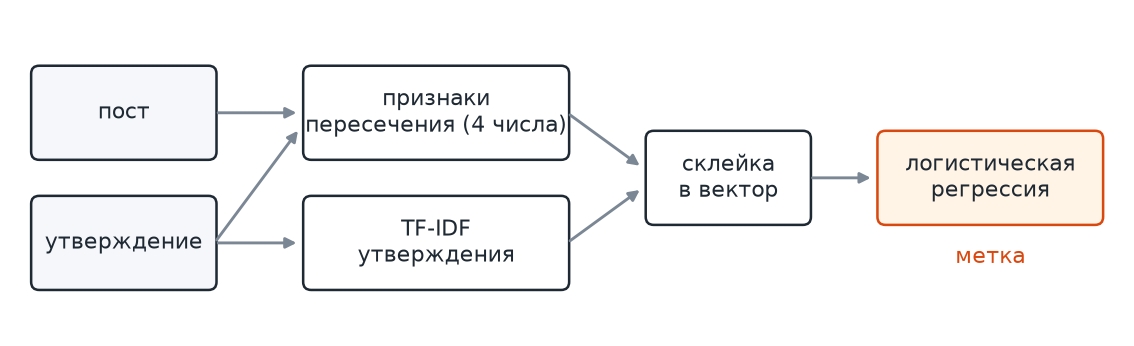

### Признаки пересечения

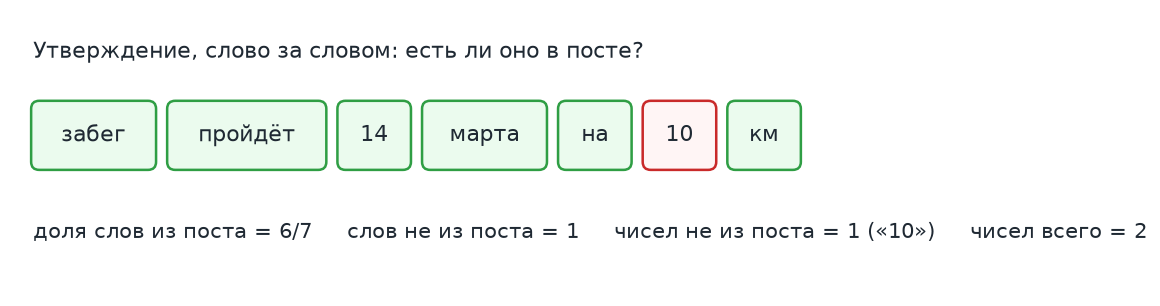

In [3]:
def words(s):
    return set(re.findall(r'\w+', s.lower()))


def numbers(s):
    return set(re.findall(r'\d+', s))


def overlap_features(df):
    rows = []
    for text, claim in zip(df.text, df.claim):
        t, c, cn = words(text), words(claim), numbers(claim)
        rows.append([len(c & t) / max(len(c), 1), len(c - t), len(cn - numbers(text)), len(cn)])
    return np.array(rows, dtype=float)

### TF-IDF

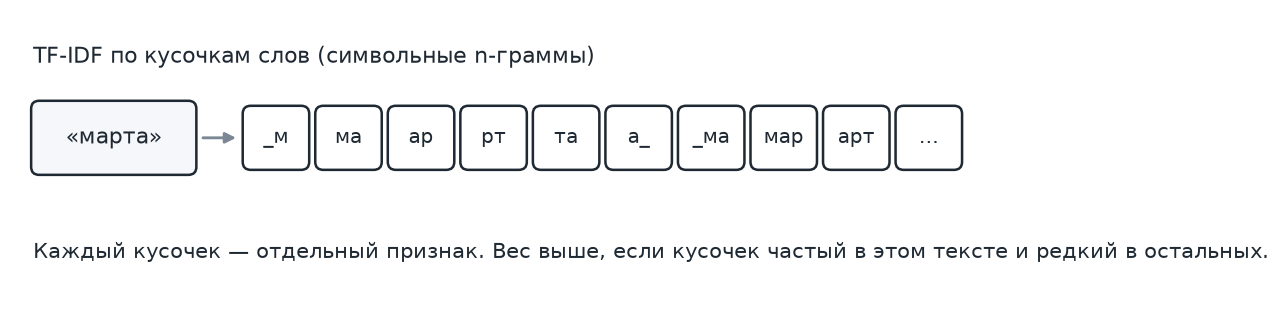

### Логистическая регрессия

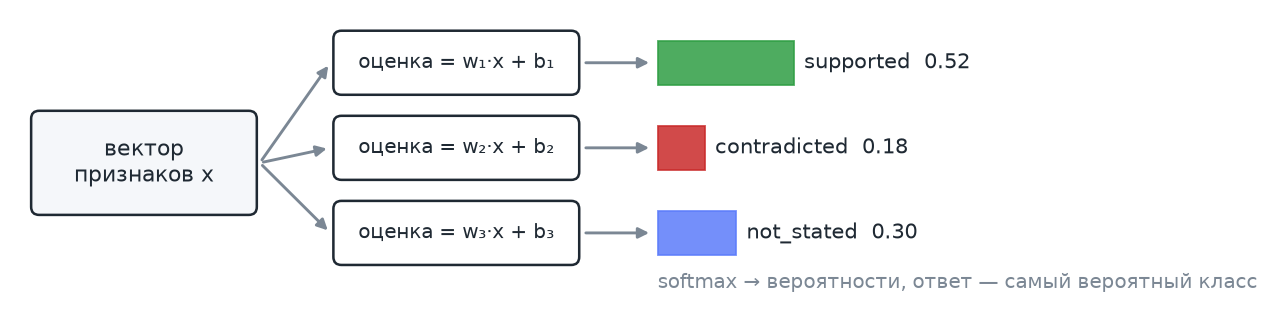

In [4]:
def fit(df):
    vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), min_df=2, sublinear_tf=True).fit(df.claim)
    clf = LogisticRegression(max_iter=3000, C=2, random_state=SEED).fit(features(vec, df), df.label)
    return vec, clf


def features(vec, df):
    return hstack([vec.transform(df.claim), csr_matrix(overlap_features(df))]).tocsr()

## Валидация

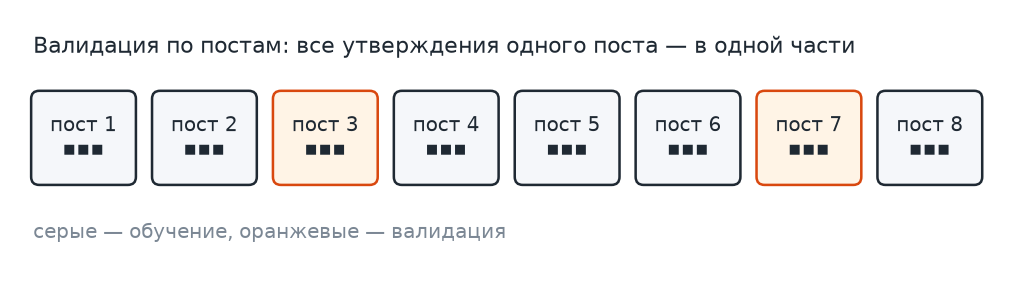

In [5]:
tr_idx, va_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(train, groups=train.text))
tr, va = train.iloc[tr_idx], train.iloc[va_idx]
vec, clf = fit(tr)
pred = clf.predict(features(vec, va))
print('macro-F1:', round(f1_score(va.label, pred, average='macro'), 4))
print(classification_report(va.label, pred, digits=3))

macro-F1: 0.4336
              precision    recall  f1-score   support

contradicted      0.465     0.324     0.382       404
  not_stated      0.422     0.479     0.449       378
   supported      0.435     0.511     0.470       409

    accuracy                          0.437      1191
   macro avg      0.441     0.438     0.434      1191
weighted avg      0.441     0.437     0.433      1191



## Сабмит

Обучаем на всём train и сохраняем `submission.csv` в формате `id,label`.

In [6]:
vec, clf = fit(train)
submission = pd.DataFrame({'id': test.id, 'label': clf.predict(features(vec, test))})
submission.to_csv('submission.csv', index=False)
submission.label.value_counts()

label
supported       1043
not_stated       974
contradicted     617
Name: count, dtype: int64